# Magic State Verification: Live Demo

**Problem.** Magic states are the expensive resource behind non-Clifford gates, and the only way to check one is by noisy, probabilistic measurements.
**Our idea.** The fidelity to |T⟩ depends only on r_x + r_z, so we measure only X and Z, and every shot becomes one bounded random variable whose mean is (F − ½)√2.
**Today.** Four levels in about 8 minutes: reconstruct, estimate, correct readout errors, and certify with a statistically valid stopping rule.

| Step | Take-away |
|---|---|
| Pitch | what we did |
| Step 1: geometry | F is a projection, so Y is irrelevant |
| Step 2: Level 1 | tomography and the physical projection |
| Step 3: Level 2 | fidelity from 200 shots, with an uncertainty |
| Step 4: Level 3 | readout errors fixed by calibration |
| Step 5: Level 4 | PASS / FAIL / INCONCLUSIVE with the shots used |
| Step 6: optional stopping | why the stopping rule is valid |

In [2]:
import math

import numpy as np
import matplotlib.pyplot as plt

import sim
import notebook_utils as nu

SEED = 7
rng = np.random.default_rng(SEED)
# Set matplotlib parameters for better visualization
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("seed", SEED)

seed 7


## The rules of the game: the state is hidden

The challenge requires the algorithm to treat ρ as unknown. Our estimators in `sim.py` receive only arrays of ±1 outcomes. In this demo the state lives inside a `HiddenDevice` that only offers three operations: measure, measure a calibration state, and sample. We call `.reveal()` only after an estimate has been made, to score it.

In [3]:
# Create a hidden device with a random Bloch vector and a given fidelity
dev = nu.HiddenDevice(nu.random_bloch(rng, 0.8), rng)
print(dev) # the state is not visible
# List the public methods and attributes of the device
print(sorted(m for m in dir(dev) if not m.startswith("_")))

HiddenDevice(state hidden)
['measure', 'measure_reference', 'reveal', 'sample', 'shots']


## Step 1: Geometry of the problem

The grey arrow is the target direction n. The fidelity is F = ½(1 + r·n), so it depends only on how far the Bloch vector points along n. The dashed line is F = 0.95, and every state in the green region passes. The depolarized state and the coherently rotated state sit on the same line: same fidelity, different kind of noise. The y-axis is not drawn because n has no y component, so **Y measurements cannot change F**.

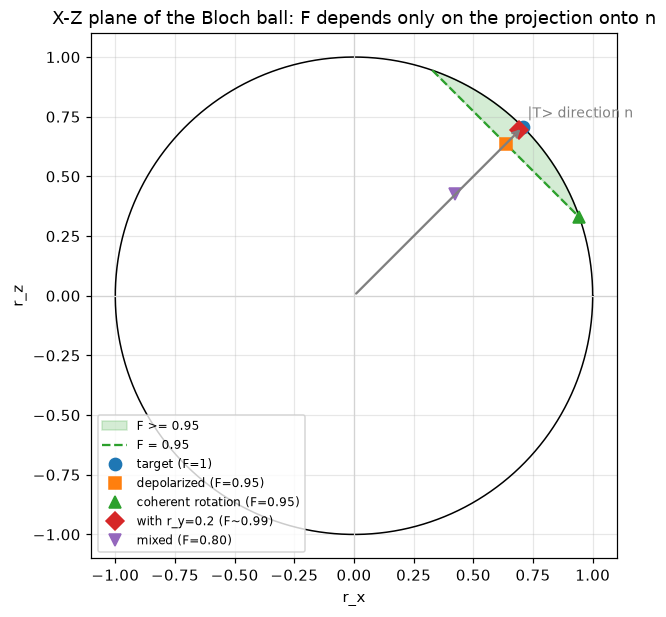

In [4]:
# Create a state zoo with a variety of states for testing
zoo = nu.state_zoo()

# Plot the X-Z plane of the Bloch ball with points from the state zoo
fig, ax = plt.subplots(figsize=(6.2, 6.2))
nu.plot_xz_disk(ax, points=zoo, thresh=0.95)
ax.set_title("X-Z plane of the Bloch ball: F depends only on the projection onto n")
plt.show()

## Step 2: Level 1, reconstruct the state

A fresh hidden device. We measure X, Y and Z 300 times each; the sample means give a raw Bloch vector. If its length exceeds 1 the matrix would not be a valid state, so we rescale it to length 1, which is the closest physical state. Then we reveal the truth and compare: trace distance ≈ 0.054 using 900 shots. Finally, the line below shows how often the projection is actually needed for a pure state 55% of the time in this run, so it is an essential step rather than a technicality.

raw Bloch estimate : [-0.507 -0.34  -0.493]   |r_hat| = 0.785
rho_hat:
 [[ 0.253+0.j   -0.253+0.17j]
 [-0.253-0.17j  0.747+0.j  ]]
Hermitian, trace 1, PSD: True

true Bloch vector   : [-0.506 -0.258 -0.563]
trace distance      : 0.0538   (shots used: 900)


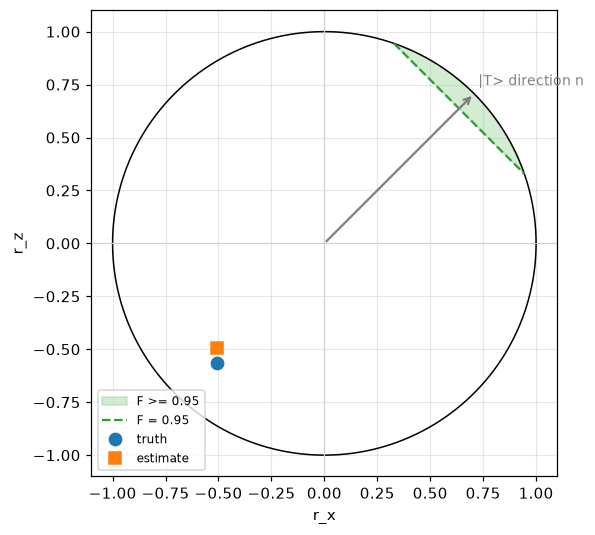

In [5]:
# Now we will perform measurements on the hidden device and reconstruct the state from the measurement outcomes.
dev = nu.HiddenDevice(nu.random_bloch(rng, 0.8), rng)
# Set the number of shots for each measurement
n = 300
# Perform measurements in the X, Y, and Z bases
outX, outY, outZ = dev.measure("X", n), dev.measure("Y", n), dev.measure("Z", n)

# Compute the raw Bloch vector estimate from the measurement outcomes and reconstruct the density matrix
raw = np.array([outX.mean(), outY.mean(), outZ.mean()])
rho_hat = sim.reconstruct(outX, outY, outZ)
# Print the raw Bloch vector estimate, the reconstructed density matrix, and check if the density matrix is physical (Hermitian, trace 1, and positive semi-definite)
print("raw Bloch estimate :", raw.round(3), "  |r_hat| =", round(float(np.linalg.norm(raw)), 3))
print("rho_hat:\n", rho_hat.round(3))
print("Hermitian, trace 1, PSD:", nu.check_physical(rho_hat))

# Now we will reveal the true Bloch vector of the hidden device and compute the trace distance between the true density matrix and the reconstructed density matrix.
r_true = dev.reveal()
rho_true = sim.rho_from_bloch(r_true)
print("\ntrue Bloch vector   :", r_true.round(3))
print(f"trace distance      : {nu.trace_distance_rho(rho_true, rho_hat):.4f}   (shots used: {dev.shots})")

# Finally, we will plot the true Bloch vector and the estimated Bloch vector on the X-Z plane of the Bloch ball.
fig, ax = plt.subplots(figsize=(5.5, 5.5))
nu.plot_xz_disk(ax, points={"truth": r_true, "estimate": nu.bloch_from_rho(rho_hat)})
plt.show()

In [6]:
# How often is the projection needed?
r = nu.target_state()
needs = np.mean([np.linalg.norm([sim.measure(r, P, 100, rng).mean() for P in "XYZ"]) > 1 for _ in range(2000)])
print(f"pure state: raw estimate has |r_hat| > 1 in {needs:.0%} of runs, so the projection is essential there")

pure state: raw estimate has |r_hat| > 1 in 55% of runs, so the projection is essential there


## Step 3: Level 2, estimate the fidelity

First the PDF's own example, which we reproduce exactly (F̂ = 0.988). Then a hidden device with a state at F = 0.95: 200 shots, 100 in X and 100 in Z. We report the estimate with a standard error computed *from the data* (a plug-in variance), then reveal the truth. The histogram is the distribution of the estimator over 3,000 repeats; it matches the normal prediction except for the spike at 1.0, where we clip. The bar chart compares the three allocations. They are close for this state, because adaptive allocation only helps when r_x and r_z differ.

In [7]:
# Now we will demonstrate the fidelity estimation using the PDF method and compare it with the true fidelity of a coherent state.
x = np.array([1] * 84 + [-1] * 16)
z = np.array([1] * 85 + [-1] * 15)
print("PDF example: F_hat =", round(float(sim.estimate_fidelity(x, z)), 3), "(the PDF says 0.988)")

# Now we will create a hidden device with a coherent state and perform measurements to estimate the fidelity. We will also compute the standard error of the estimate and compare it with the true fidelity of the state.
dev = nu.HiddenDevice(nu.coherent_state(0.95), rng)
N = 200
x = dev.measure("X", N // 2)
z = dev.measure("Z", N - N // 2)
F_hat = float(sim.estimate_fidelity(x, z))
se = math.sqrt(((1 - x.mean() ** 2) / len(x) + (1 - z.mean() ** 2) / len(z)) / 8)   # plug-in standard error
print(f"estimate: F_hat = {F_hat:.3f} +/- {se:.3f} (1 s.e.),  shots used = {dev.shots}")

F_true = sim.fidelity(dev.reveal())
print(f"truth   : F = {F_true:.3f}   |error| = {abs(F_hat - F_true):.3f} = {abs(F_hat - F_true) / se:.1f} standard errors")

PDF example: F_hat = 0.988 (the PDF says 0.988)
estimate: F_hat = 0.988 +/- 0.034 (1 s.e.),  shots used = 200
truth   : F = 0.950   |error| = 0.038 = 1.1 standard errors


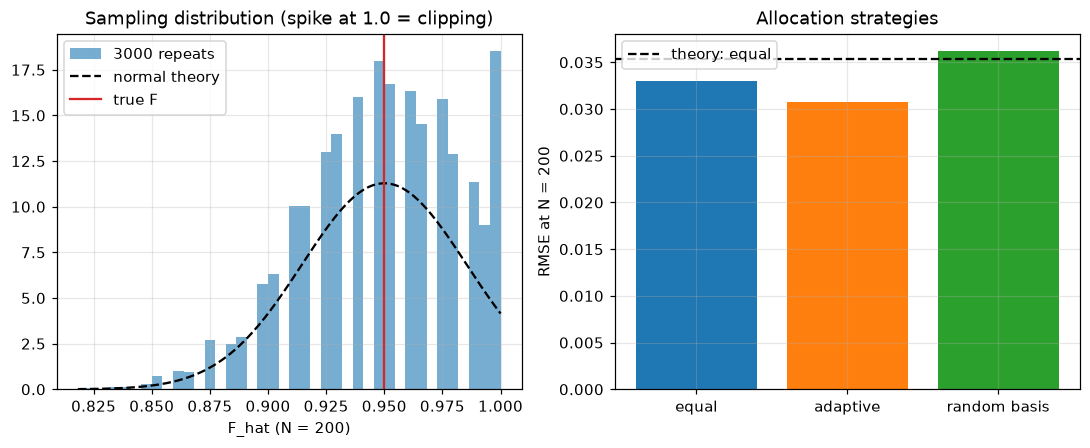

In [8]:
r_demo = nu.coherent_state(0.95)
F_true = sim.fidelity(r_demo)
N = 200
ests = np.array([float(sim.estimate_fidelity(sim.measure(r_demo, "X", N // 2, rng), sim.measure(r_demo, "Z", N // 2, rng)))
                 for _ in range(3000)])
sigma = nu.sigma_equal(r_demo, N)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(ests, bins=40, density=True, alpha=0.6, label="3000 repeats")
xs = np.linspace(ests.min(), ests.max(), 300)
axes[0].plot(xs, np.exp(-0.5 * ((xs - F_true) / sigma) ** 2) / (sigma * math.sqrt(2 * math.pi)), "k--", label="normal theory")
axes[0].axvline(F_true, color="tab:red", label="true F")
axes[0].set(xlabel="F_hat (N = 200)", title="Sampling distribution (spike at 1.0 = clipping)")
axes[0].legend()

methods = ("equal", "adaptive", "random basis")
def trial(m):
    if m == "equal":
        return float(sim.estimate_fidelity(sim.measure(r_demo, "X", N // 2, rng), sim.measure(r_demo, "Z", N // 2, rng)))
    if m == "adaptive":
        return float(sim.estimate_fidelity_adaptive(r_demo, N, rng, pilot=N // 20))
    return float(sim.estimate_fidelity_random_basis(r_demo, N, rng))
rm = [nu.rmse_bias_se([trial(m) - F_true for _ in range(1500)])[2] for m in methods]
axes[1].bar(methods, rm, color=["tab:blue", "tab:orange", "tab:green"])
axes[1].axhline(nu.sigma_equal(r_demo, N), color="k", ls="--", label="theory: equal")
axes[1].set(ylabel="RMSE at N = 200", title="Allocation strategies")
axes[1].legend()
plt.show()

## Step 4: Level 3, readout errors

The apparatus now has a hidden readout error that shrinks every ⟨P⟩ by a factor b (here 0.90, a 5% flip rate). If we ignore it, the estimate is biased low by about 0.045 for states near F = 0.95, and more shots cannot fix that. So we spend 30% of the 2,000-shot budget measuring known +1 and −1 eigenstates, estimate b for each basis (we get ≈ 0.95 and ≈ 0.87 in the default run, noisy because only 150 shots go to each reference state), and divide it out. The calibration shots come out of the same budget, so the comparison is fair. The bootstrap interval resamples the calibration data as well, so it includes calibration uncertainty. In the default run the calibrated estimate lands close to the truth with an interval that contains it, while the uncorrected one sits visibly low.

estimated contrast b_X = 0.947, offset a_X = +0.013
estimated contrast b_Z = 0.873, offset a_Z = -0.007

uncorrected: 0.915 +/- 0.013
calibrated : 0.947   95% bootstrap CI [0.899, 0.990]
truth      : 0.950


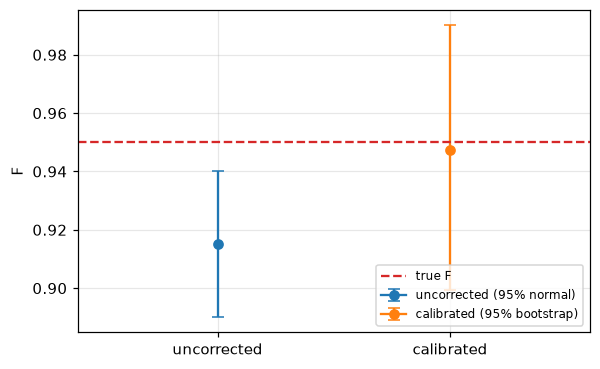

In [9]:
dev = nu.HiddenDevice(nu.on_axis_state(0.95), rng, a=0.0, b=0.90)      # hidden readout error
N, f_cal = 2000, 0.3

# uncorrected: all N shots on the state, no calibration
x, z = dev.measure("X", N // 2), dev.measure("Z", N // 2)
F_unc = float(sim.estimate_fidelity(x, z))
se_unc = math.sqrt(((1 - x.mean() ** 2) / len(x) + (1 - z.mean() ** 2) / len(z)) / 8)

# calibrated: same total budget, 30% of it on known eigenstates
data = nu.collect_data_device(dev, N, f_cal)
F_cal = sim.fidelity_from_data(data)
lo, hi = sim.bootstrap_ci(data, rng, n_boot=1000)
for P in "XZ":
    m_plus, m_minus = data["cal"][(P, +1)].mean(), data["cal"][(P, -1)].mean()
    print(f"estimated contrast b_{P} = {(m_plus - m_minus) / 2:.3f}, offset a_{P} = {(m_plus + m_minus) / 2:+.3f}")

F_true = sim.fidelity(dev.reveal())
print(f"\nuncorrected: {F_unc:.3f} +/- {se_unc:.3f}")
print(f"calibrated : {F_cal:.3f}   95% bootstrap CI [{lo:.3f}, {hi:.3f}]")
print(f"truth      : {F_true:.3f}")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.errorbar([0], [F_unc], yerr=[1.96 * se_unc], marker="o", capsize=4, label="uncorrected (95% normal)")
ax.errorbar([1], [F_cal], yerr=[[F_cal - lo], [hi - F_cal]], marker="o", capsize=4, label="calibrated (95% bootstrap)")
ax.axhline(F_true, color="tab:red", ls="--", label="true F")
ax.set(xlim=(-0.6, 1.6), xticks=[0, 1], xticklabels=["uncorrected", "calibrated"], ylabel="F")
ax.legend(loc="lower right", fontsize=8)
plt.show()

## Step 5: Level 4, certify F ≥ 0.95

Three hidden devices whose fidelities we do not look at. For each we run the sequential protocol: shots arrive in batches that double, and after each batch we build a confidence interval for F. We stop when the interval lies entirely above 0.95 (PASS) or entirely below (FAIL), or at 20,000 shots (INCONCLUSIVE). Each look spends a share of the error budget δ = 0.05, so the total probability of a wrong decision is at most δ even though we decide when to stop. In the default run, device 1 passes at 6,400 shots, device 2 fails at 6,400 shots, and device 3, sitting right at the threshold, is correctly inconclusive at the 20,000-shot cap. A state exactly at the threshold cannot be decided with finitely many shots.

In [10]:
fids = [0.99, 0.90, 0.95]
runs = []
for F in fids:
    dev = nu.HiddenDevice(nu.on_axis_state(F), rng)          # F is known to us only to build the device
    decision, (lo, hi), n_used, hist = nu.certify_trace(dev.sample, thresh=0.95, delta=0.05)
    runs.append((decision, hist, dev.shots))
    print(f"device {len(runs)}: {decision:12s} interval [{lo:.3f}, {hi:.3f}]   shots used = {n_used}")

device 1: PASS         interval [0.950, 1.000]   shots used = 6400
device 2: FAIL         interval [0.877, 0.946]   shots used = 6400
device 3: INCONCLUSIVE interval [0.928, 0.968]   shots used = 20000


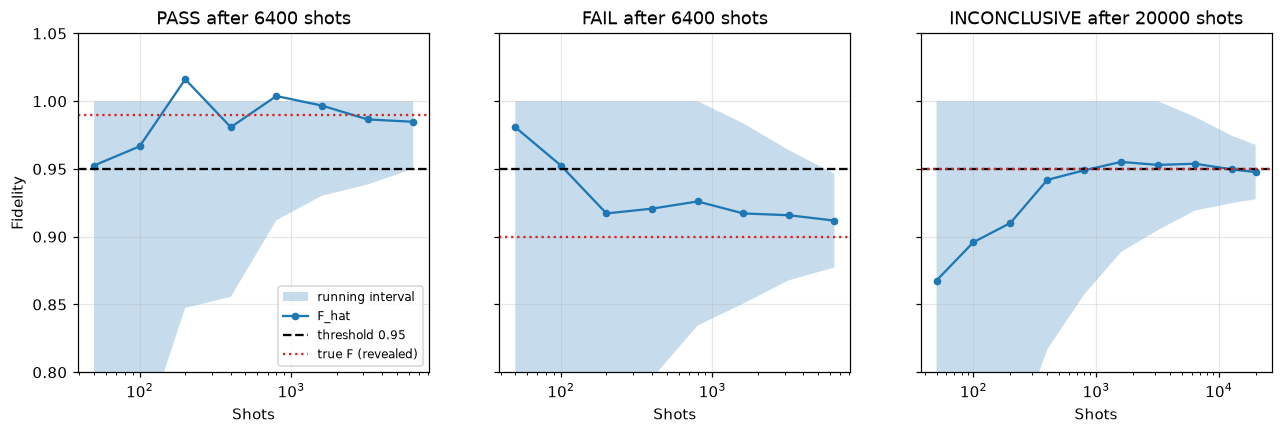

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, F, (decision, hist, shots) in zip(axes, fids, runs):
    N_k, F_hat, lo, hi = hist.T
    ax.fill_between(N_k, lo, hi, alpha=0.25, label="running interval")
    ax.plot(N_k, F_hat, "o-", ms=4, label="F_hat")
    ax.axhline(0.95, color="k", ls="--", label="threshold 0.95")
    ax.axhline(F, color="tab:red", ls=":", label="true F (revealed)")
    ax.set(xscale="log", xlabel="Shots", title=f"{decision} after {shots} shots")
axes[0].set_ylabel("Fidelity")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].set_ylim(0.8, 1.05)
plt.show()

## Step 6: Why the stopping rule is valid (optional stopping)

Stopping early is dangerous: a fixed 95% interval checked after every batch will sooner or later wander across the threshold by chance. Here the true fidelity is 0.945, just *below* 0.95, so every PASS is a wrong answer. We compare three rules: a naive normal interval checked every 50 shots, the same rule with the error budget spent across looks, and our Hoeffding protocol. In the default run the naive rule falsely passes 19% of the time, spending reduces that to 5%, and Hoeffding gives 0%, at the price of more shots. The normal rules have no finite-sample guarantee, so their numbers can shift with the seed; Hoeffding's guarantee does not. We chose validity over efficiency.

naive normal               false-PASS  19.0%   mean shots    5666
alpha-spending normal      false-PASS   5.0%   mean shots   18339
alpha-spending Hoeffding   false-PASS   0.0%   mean shots   20000


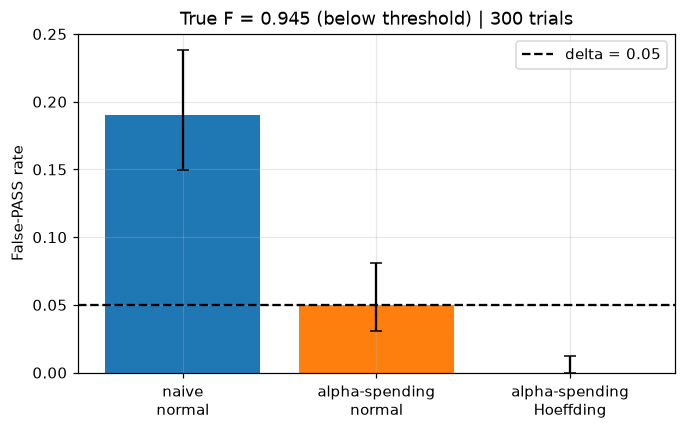

In [12]:
TRIALS_OS = 300
F_below = 0.945
res = nu.optional_stopping_experiment([F_below], TRIALS_OS, rng, thresh=0.95, delta=0.05)
fig, ax = plt.subplots(figsize=(7, 4))
for i, name in enumerate(nu.RULE_NAMES):
    k = res[name]["passes"][0]
    p = k / TRIALS_OS
    lo, hi = nu.wilson(k, TRIALS_OS)
    ax.bar(i, p, yerr=[[p - lo], [hi - p]], capsize=4)
    print(f"{name:26s} false-PASS {p:6.1%}   mean shots {res[name]['mean_shots'][0]:7.0f}")
ax.axhline(0.05, color="k", ls="--", label="delta = 0.05")
ax.set(xticks=range(3), xticklabels=[n.replace(" ", "\n", 1) for n in nu.RULE_NAMES], ylabel="False-PASS rate",
       title=f"True F = {F_below} (below threshold) | {TRIALS_OS} trials")
ax.legend()
plt.show()